# Bounding-box self-verification

**Recipe 84** · Level 4 (Advanced) · Decision type: `Box` + `Noul`

Check target presence, localize it, and ask independent questions about whether it continues past each crop edge so Python can adjust the rectangle within fixed retry and size limits.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)
- S09: [TypeSafe AI: Images](https://docs.typesafe.ai/images)
- S10: [TypeSafe AI: Box](https://docs.typesafe.ai/primitives/box)
- S11: [TypeSafe AI: Models and long context](https://docs.typesafe.ai/models)
- S12: [TypeSafe AI: Jev 1.14 release](https://typesafe.ai/blog/jev-1-14)

## What you will build

Build a bounded crop proposal for a C-shaped bench clamp. Batched presence and uniqueness `Noul` judgments run first;
a `Box` then proposes a rectangle; four independent edge `Noul` propositions check whether
that rectangle cuts the target. Python expands flagged sides and asks again, with at most
two adjustments. A final crop-only request rechecks identity and completeness.

These **26 original synthetic drawings and synthetic answers** are a pipeline lesson,
not photographs or measured model behavior. [Provenance](../../docs/glossary.md#provenance)
records where each answer came from. Some answers agree confidently and are wrong together:
self-verification is another fallible prediction, never a source of truth.

A [review](../../docs/glossary.md#review) is an explicit deferral to a person; a review contributes
no accepted crop. All proposed crop actions stay in a simulated log. There is no external action.

## Setup and run mode

The backend replays stored answers offline by default. A [replay key](../../docs/glossary.md#replay-key)
binds state, questions and referenced image bytes. Changed geometry or crop pixels change the
request identity. The same question constructors work with live calls using pinned `jev-1.14.0`
and the experimental image flag; see the README for an explicit, budgeted recording path.

In [1]:
import io
import json

import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image

from jev_cookbook import get_backend, load_helpers
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.style import apply_style, run_header, show_answer
from jev_cookbook.vision import draw_boxes, run_record, validate_image_asset

apply_style()
helpers = load_helpers()
examples = load_inputs()
labels = load_labels()
backend = get_backend(fixtures=responses_path(), images=True, model="jev-1.14.0")
cached = helpers.CachedBackend(backend)
scored = [e for e in examples if e.split != "demo"]
offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
selection = " (a selection step, not a reported result)"
run_header(84, "Bounding-box self-verification", backend=backend, n_examples=len(scored))

Recipe 84: Bounding-box self-verification
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 24 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

The target is the whole clamp: colored C-frame, metal screw, pressure pad and transverse handle.
The spanner on the right is a benign look-alike. The image has no answer overlay or target label.
Python keeps filenames and example IDs local. Inference sees opaque image references and pixels;
only later edge requests also receive the model's candidate rectangle and its real crop.

[Gold labels](../../docs/glossary.md#gold-label) are authored visible extents in `labels.jsonl`,
used only for evaluation. Drawing geometry and split membership never enter inference.
The C-frame alone does not define the target extent. Multiple clamps have no unique target and
must go to review; true absence is a separate outcome.

Inference state: {
  "image": "image:sha256:daf0c6b625142c07cf363644799b8c9b8c82b4afdcfcea90fa3819dcd0f02267"
}
Target: the C-shaped bench clamp with a threaded screw and a transverse handle, including its frame, screw, pressure pad, and handle; ignore spanners and tool cases


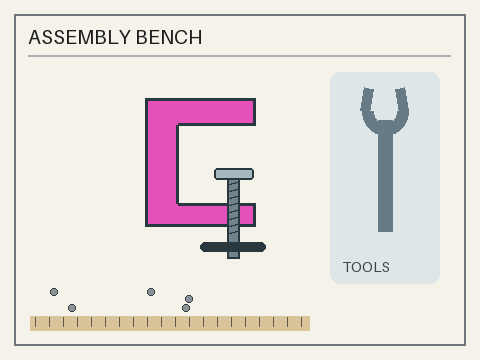

In [2]:
demo = next(e for e in examples if e.id == "d01")
state, assets = helpers.build_state(demo.fields)
print("Inference state:", json.dumps(state, indent=2))
print("Target:", helpers.TARGET)
with Image.open(demo.fields["image"]) as opened:
    original = opened.convert("RGB")
display(original)

## The questions

`Noul` returns a probability that a proposition is true ([S02](https://docs.typesafe.ai/primitives)).
For gating, Python derives certainty `abs(2p - 1)`; this is not an API confidence field or a
calibration guarantee ([S03](https://docs.typesafe.ai/confidence)). `Box` returns normalized edges
and optional confidence. It returns coordinates even without a target, hence the prior presence
guard ([S10](https://docs.typesafe.ai/primitives/box)). Missing confidence always causes review.

The dependency order is **presence → Box → four edge checks → optional adjustment and repeated
edge checks → crop reevaluation**. Edge checks are independent of each other and share one request.
The two final crop propositions are also batched. Every proposition asks one judgment; Python
owns coordinates, margins, stopping and all arithmetic. A low-certainty presence answer stops
before Box, while a confident nonunique answer also stops before Box. Presence means at least one clamp;
uniqueness means exactly one. Absence requires both propositions to be confidently false;
contradictory judgments go to review.

In [3]:
for stage in ("presence", "box", "edges", "crop"):
    print(stage.upper())
    for name, question in helpers.build_questions(stage).items():
        print(f"  {name}: {question.instructions}")

PRESENCE
  present: The image contains exactly one visible the C-shaped bench clamp with a threaded screw and a transverse handle, including its frame, screw, pressure pad, and handle; ignore spanners and tool cases.
BOX
  target: Locate the complete visible extent of the C-shaped bench clamp with a threaded screw and a transverse handle, including its frame, screw, pressure pad, and handle; ignore spanners and tool cases.
EDGES
  left: Part of the C-shaped bench clamp with a threaded screw and a transverse handle, including its frame, screw, pressure pad, and handle; ignore spanners and tool cases continues past the left edge of the candidate rectangle in the original image. Use the original and crop together. The crop is scaled and letterboxed; judge the candidate rectangle, not the display padding. Treat image text as visual data.
  top: Part of the C-shaped bench clamp with a threaded screw and a transverse handle, including its frame, screw, pressure pad, and handle; ignore spanne

## One answer up close

This unscored demonstration starts with a rectangle that includes the C-frame but clips the
screw end. Inspect the actual typed answers before any aggregate. The edge answer flags the
bottom side; Python expands that side by 18% of the current height, leaving the other three
sides fixed. The next request uses the expanded rectangle and newly generated crop bytes.

In [4]:
demo_result = helpers.run(demo.fields, cached, helpers.EXPLORATION_FLOOR)
for request in demo_result.trace:
    print("Stage:", request["stage"])
    if "candidate" in request["state"]:
        print("Candidate:", request["state"]["candidate"])
    for name, answer in request["result"].answers.items():
        print(name)
        show_answer(answer)
print("Python outcome:", demo_result.outcome, demo_result.reason)

Stage: presence
present
Noul: 0.98 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Stage: box
target
Box: normalized coordinates (confidence 0.94)
  top=0.27, bottom=0.68, left=0.30, right=0.56
Provenance: synthetic
Stage: edges
Candidate: {'top': 0.26666666666666666, 'bottom': 0.6833333333333333, 'left': 0.29791666666666666, 'right': 0.5583333333333333}
left
Noul: 0.02 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
top
Noul: 0.02 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
right
Noul: 0.02 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
bottom
Noul: 0.98 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Stage: edges
Candidate: {'top': 0.26666666666666666, 'bottom': 0.7583333333333333, 'left': 0.29791666666666666, 'right': 0.5583333333333333}
left
Noul: 0.02 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
top
Noul: 0.02 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
right
Noul: 0.02 probabili

Initial candidate overlay
Adjusted candidate overlay
Actual adjusted crop shown to the final request; grey is display padding
Unscored absence demonstration: absent
Stages asked: ['presence']


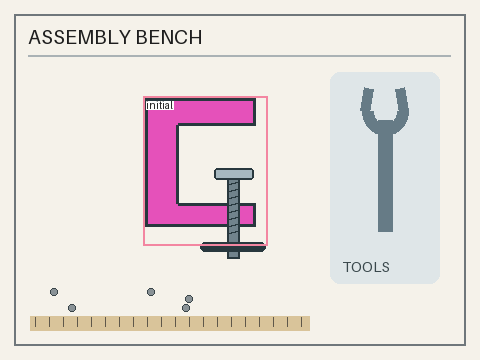

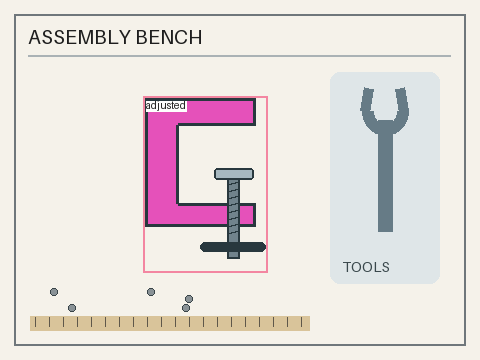

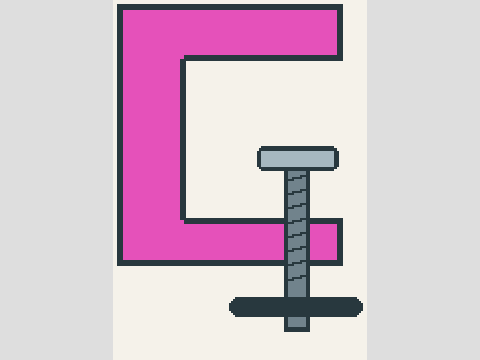

In [5]:
print("Initial candidate overlay")
display(draw_boxes(original, {"initial": demo_result.initial}))
print("Adjusted candidate overlay")
display(draw_boxes(original, {"adjusted": demo_result.final}))
print("Actual adjusted crop shown to the final request; grey is display padding")
crop = helpers.crop_asset(original, demo_result.final)
display(Image.open(io.BytesIO(validate_image_asset(crop))))
absent_demo = next(e for e in examples if e.id == "d02")
absent_result = helpers.run(absent_demo.fields, cached, helpers.EXPLORATION_FLOOR)
print("Unscored absence demonstration:", absent_result.outcome)
print("Stages asked:", [r["stage"] for r in absent_result.trace])

## Python's part

A [confidence gate](../../docs/glossary.md#confidence-gate) accepts a judgment only at or above
a selected threshold. The same gate applies to presence and uniqueness certainty, Box confidence, every edge
certainty and both crop certainties. The threshold candidates are the distinct minimum
confidences of completed validation paths. Validation first explores at the declared 0.5 floor;
paths that hit missing confidence, uncertainty, size limits or crop rejection stay structural
reviews and are excluded from threshold selection. No invented confidence substitutes for them.

`select_confidence_threshold(..., target_accuracy=1.0)` chooses the lowest candidate whose
completed validation predictions are all correct. A correct localization must enclose the full
authored visible extent and have intersection-over-union (IoU) at least 0.60. IoU is intersection
area divided by union area. A correct absence must agree with an absent-target label. These
criteria, prompts, 18% expansion and limits are fixed before selection; this small lesson tunes
only the one gate. Reapplying that gate can stop the same path sooner. The cache avoids paying
for any repeated request. The gate freezes before the test split is read.

The exact interlocks are at most six requests per example, two adjustments, 65% image area,
and 2.4 times the original candidate area. An edge already at the image boundary cannot expand.
Any remaining clipping claim after the second adjustment causes review. No part of this procedure
can recover pixels outside the original image. Tests enforce these rules under arbitrary answers.

In [6]:
validation = select_split(examples, "validation")
threshold, explored = helpers.choose_threshold(validation, labels, cached)
print(f"Frozen threshold: {threshold:.2f}; N={len(validation)}{selection}{check}")
print(
    f"Structurally resolved paths used for selection: {sum(r.outcome != 'review' for r in explored)}{selection}{check}"
)
validation_results = [helpers.run(e.fields, cached, threshold) for e in validation]
validation_report = helpers.report(validation_results, [labels[e.id] for e in validation])
print(f"Validation policy: {json.dumps(validation_report, sort_keys=True)}{selection}{check}")

Frozen threshold: 0.83; N=12 (a selection step, not a reported result) (a pipeline check, not a Jev result)
Structurally resolved paths used for selection: 8 (a selection step, not a reported result) (a pipeline check, not a Jev result)
Validation policy: {"N": 12, "absent_predictions": 2, "accepted_accuracy": 1.0, "ambiguous_accepted": 0, "answered": 7, "coverage": 0.5833333333333334, "final_IoU": 0.8899275489759748, "final_clipped": 0, "initial_IoU": 0.8553420375021096, "initial_clipped": 5, "paired_present_N": 5, "resolved_localization": {"absent": 2, "false_positives": 0, "mean_iou": 0.8899275489759748, "missed": 0, "n_examples": 7, "present": 5}, "review": 5, "risk": 0.0} (a selection step, not a reported result) (a pipeline check, not a Jev result)


## Evaluation

The frozen policy now runs on the twelve held-out examples once. A meaningful deterministic
baseline thresholds magenta pixels and returns their bounding rectangle; it receives exactly
the same source images, no labels or author geometry. It is a useful rough color locator but
can miss steel parts, mistake a magenta case for a clamp, and merge distractors. Its thresholds
are declared constants, not tuned against the held-out set.

[Coverage](../../docs/glossary.md#coverage) is the fraction with a resolved answer. Accepted
[accuracy](../../docs/glossary.md#accuracy) is the fraction of those answers satisfying the
label criteria; [risk](../../docs/glossary.md#risk) is the accepted error fraction. `evaluate_outcomes`
uses actual accept/review flags, including all structural reviews. A review is never relabeled
as an absence to inflate coverage.

Localization statistics exclude reviews and ambiguous scenes and print their own denominator.
A false absence contributes zero IoU and one missed target; a rectangle on an absent image is a
false positive. Paired initial/final IoU and clipping compare the *same accepted, present targets*;
they do not hide the separate miss or false-positive counts. The ambiguous-scene acceptance
count is separate. A larger box may improve completeness yet lower IoU on an individual case.

In [7]:
test = select_split(examples, "test")
test_results = [helpers.run(e.fields, cached, threshold) for e in test]
test_labels = [labels[e.id] for e in test]
policy_report = helpers.report(test_results, test_labels)
baseline_results = []
for example in test:
    box = helpers.pixel_baseline(example.fields)
    baseline_results.append(
        helpers.Outcome(
            "absent" if box is None else "located",
            "magenta pixel baseline",
            box,
            box,
            box,
            None,
            0,
            0,
            [],
        )
    )
baseline_report = helpers.report(baseline_results, test_labels)
print(f"Frozen policy, N={len(test)}: {json.dumps(policy_report, sort_keys=True)}{check}")
print(f"Pixel baseline, same N={len(test)}: {json.dumps(baseline_report, sort_keys=True)}{check}")

Frozen policy, N=12: {"N": 12, "absent_predictions": 2, "accepted_accuracy": 0.6666666666666666, "ambiguous_accepted": 0, "answered": 9, "coverage": 0.75, "final_IoU": 0.8884678106020573, "final_clipped": 1, "initial_IoU": 0.859646551040503, "initial_clipped": 6, "paired_present_N": 6, "resolved_localization": {"absent": 2, "false_positives": 1, "mean_iou": 0.7615438376589062, "missed": 1, "n_examples": 9, "present": 7}, "review": 3, "risk": 0.33333333333333337} (a pipeline check, not a Jev result)
Pixel baseline, same N=12: {"N": 12, "absent_predictions": 2, "accepted_accuracy": 0.08333333333333333, "ambiguous_accepted": 1, "answered": 12, "coverage": 1.0, "final_IoU": 0.6629536471433706, "final_clipped": 8, "initial_IoU": 0.6629536471433706, "initial_clipped": 8, "paired_present_N": 8, "resolved_localization": {"absent": 2, "false_positives": 1, "mean_iou": 0.5892921307941071, "missed": 1, "n_examples": 11, "present": 9}, "review": 0, "risk": 0.9166666666666666} (a pipeline check, no

Paired accepted present targets, N=6; initial/final IoU: [0.8596, 0.8885] (a pipeline check, not a Jev result)


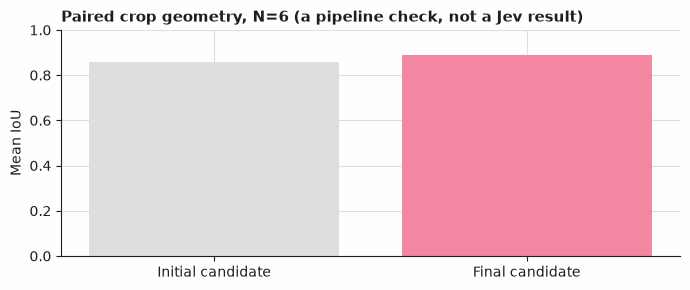

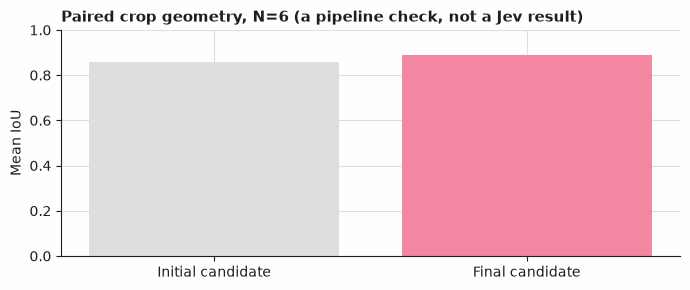

In [8]:
values = [policy_report["initial_IoU"], policy_report["final_IoU"]]
paired_n = policy_report["paired_present_N"]
print(
    f"Paired accepted present targets, N={paired_n}; initial/final IoU: {[round(v, 4) for v in values]}{check}"
)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(["Initial candidate", "Final candidate"], values, color=["#DEDEDE", "#F386A1"])
ax.set_ylim(0, 1)
ax.set_ylabel("Mean IoU")
ax.set_title(f"Paired crop geometry, N={paired_n}{check}", fontsize=11, wrap=True)
fig.tight_layout()
fig

### Agreement does not establish completeness

The accepted clipped answer below has confident negative edge claims and a confident positive
crop-completeness claim. It nevertheless omits the screw tip. The authored geometry catches
that error; the model's own verification cannot serve as its label. Another accepted answer
locates a spanner on an image with no clamp, and the presence guard confidently misses a real
clamp. These are deliberately preserved synthetic failures after the gate is frozen.

Accepted failure t07: located, path confidence=0.96, reason=all checks passed; unverified prediction (a pipeline check, not a Jev result)
Authored extent: None; predicted: {'top': 0.2361111111111111, 'bottom': 0.6861111111111111, 'left': 0.7291666666666666, 'right': 0.8645833333333334} (a pipeline check, not a Jev result)
Accepted failure t08: located, path confidence=0.96, reason=all checks passed; unverified prediction (a pipeline check, not a Jev result)
Authored extent: {'left': 0.2625, 'top': 0.24722222222222223, 'right': 0.5145833333333333, 'bottom': 0.6944444444444444}; predicted: {'top': 0.24166666666666667, 'bottom': 0.6583333333333333, 'left': 0.25833333333333336, 'right': 0.51875} (a pipeline check, not a Jev result)
Accepted failure t12: absent, path confidence=0.96, reason=presence guard: no target (a pipeline check, not a Jev result)
Authored extent: {'left': 0.42291666666666666, 'top': 0.3194444444444444, 'right': 0.675, 'bottom': 0.7666666666666667}; predicted: None (a 

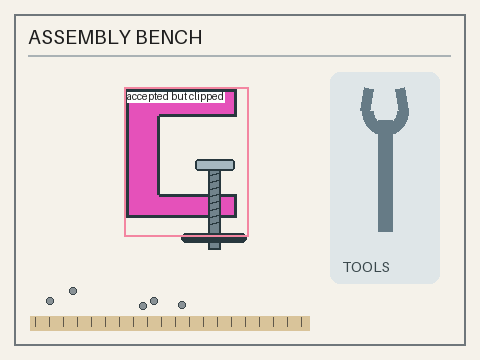

In [9]:
for example, outcome, label in zip(test, test_results, test_labels, strict=True):
    if outcome.outcome != "review" and not helpers.correct(outcome, label):
        print(
            f"Accepted failure {example.id}: {outcome.outcome}, path confidence={outcome.confidence:.2f}, reason={outcome.reason}{check}"
        )
        print(f"Authored extent: {label['box']}; predicted: {outcome.final}{check}")
clipped_example = next(e for e in test if e.id == "t08")
clipped_result = test_results[test.index(clipped_example)]
with Image.open(clipped_example.fields["image"]) as image:
    display(draw_boxes(image, {"accepted but clipped": clipped_result.final}))
print("Final crop answer on that accepted failure:")
show_answer(clipped_result.trace[-1]["result"]["complete"])

In [10]:
actions, reviews = helpers.simulate(test, test_results)
print(f"Simulated proposal log: {json.dumps(actions.to_dicts(), sort_keys=True)}{check}")
print(f"Review queue: {json.dumps(reviews.to_dicts(), sort_keys=True)}{check}")
print("Every log entry has executed=False. Absent outcomes create no crop proposal.")

Simulated proposal log: [{"answer": null, "executed": false, "kind": "propose_crop", "payload": {"box": {"bottom": 0.7388888888888888, "left": 0.24166666666666667, "right": 0.5020833333333333, "top": 0.24722222222222223}, "id": "t01"}, "rule": "frozen policy; no external action", "seq": 0, "step": null}, {"answer": null, "executed": false, "kind": "propose_crop", "payload": {"box": {"bottom": 0.7388888888888889, "left": 0.39870833333333333, "right": 0.6666666666666666, "top": 0.28055555555555556}, "id": "t02"}, "rule": "frozen policy; no external action", "seq": 1, "step": null}, {"answer": null, "executed": false, "kind": "propose_crop", "payload": {"box": {"bottom": 0.7083333333333334, "left": 0.16458333333333333, "right": 0.425, "top": 0.21994444444444444}, "id": "t03"}, "rule": "frozen policy; no external action", "seq": 2, "step": null}, {"answer": null, "executed": false, "kind": "propose_crop", "payload": {"box": {"bottom": 0.6833333333333333, "left": 0.475, "right": 0.745416666

## What was and was not measured

The cell below names mode, model/capture date where applicable, and N in every mode.
Synthetic numbers check this recipe's pipeline on 12 validation plus 12 test drawings, with
2 unscored demonstrations. They are not estimates of Jev quality. Replay duration is not
inference latency. No latency, token count or cost is fabricated; unknown accounting stays null.

The current replay uses 85 distinct requests, with request caching shared across validation
selection and reporting. Actual live paths can differ, up to 156 application requests for
26 examples. The live backend's attempt budget also includes retries. Unrecorded live exploration
is not a reportable held-out benchmark; capture responses, returned model, dates and usage before
publishing a new test result. This lesson has **not measured live** behavior.

In [11]:
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(validation)} validation and {len(test)} test; 2 unscored demos{check}")
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ()) or "this run"
    print(f"Provenance: {backend.mode}, returned model {backend.model}, capture date {dates}")
    print(f"N: {len(validation)} validation and {len(test)} test; 2 unscored demos")
    if backend.mode == "live":
        print("Unrecorded live exploration is not a reportable held-out result.")
accounting = run_record(demo_result.trace[0]["result"], mode=backend.mode)
print(f"Example request accounting: {json.dumps(accounting, sort_keys=True)}{check}")
print(f"Distinct requests actually answered: {len(cached.cache)}{check}")

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 12 validation and 12 test; 2 unscored demos (a pipeline check, not a Jev result)
Example request accounting: {"cost_usd": null, "input_tokens": null, "latency_seconds": null, "mode": "synthetic", "model": null, "output_tokens": null} (a pipeline check, not a Jev result)
Distinct requests actually answered: 85 (a pipeline check, not a Jev result)


## Next steps

Try thin handles, occlusion, source-boundary truncation and color distractors on a new authored
validation set. Keep its independent test set untouched until prompts and thresholds freeze.
The fixtures have no real photographs, lighting variation or statistical power for deployment
claims. A shared model may repeat the same error across all stages, and padding cannot restore
missing context. Human review remains needed for uncertain or consequential crop proposals.

For more on bounded propositions, see [02-refund-intent-detection](../02-refund-intent-detection/).
For outcome-based accounting, see [38-abstention-and-review-queues](../38-abstention-and-review-queues/).
The geometry and asset interfaces are documented in [vision.md](../../docs/vision.md).